# Positivity rules on the whole dataset

`whole_dataset.ipynb` counts AF488-positive cells with the **calibrated** rule chosen in `notebooks/validation/positivity_metrics.ipynb` on 30 annotated sections. This notebook asks whether the dataset's answers depend on that choice, on the final observations: the **counted** sections of the run (`run_dataset.py`), each with its primary band (hand-drawn where it exists, else the finder's).

Every rule is recomputed from the per-cell values the run stored (`cells/<name>.parquet`), without segmenting again.

**The SD rules, and where their reference comes from.** "Median + k SD" calls a cell positive when its AF488 is above the median of a reference population plus *k* robust SDs (1.4826 × MAD). The reference is the band's cells — but whose band:

| level | reference cells | what it assumes |
|---|---|---|
| **per section** | that section's band (the run's rule) | nothing is comparable between sections; each sets its own bar |
| **per slide** | the bands of every counted section on the slide, pooled | sections on one slide were stained and imaged alike |
| **per experiment** | every band in the experiment, pooled | the whole batch was stained and imaged alike |
| **whole dataset** | every band, pooled | all intensities are comparable |

A per-section bar adapts to each section's own background, but it also moves with the section's own labelling: a band full of bright cells raises its own bar. A pooled bar is the same for every section it covers, so a section with more labelled cells gets more positives — but a dim or bright slide shifts everything. Each SD level is run with two values:

- **filtered, +7 SD** — the AF488 mean over the nucleus grown 3 µm, less the 45 µm local median (the run's *calibrated* rule at section level);
- **raw, +3 SD** — the unfiltered mean (the *current* rule at section level, which the validation found overcounts).

**The other rules** (per section, no pooling): ring contrast ≥ 1.5 (the run's *contrast* check) and ≥ 2 — the cell over its own 3–6 µm ring; and the 99th percentile of a **negative control** — cells more than 300 µm into the organoid where AF488 is not at home (> 30 µm inside the tissue; nearer, 200 then 100 µm, where that organoid is small), on intensity or on contrast. GMM and Otsu are left out: they failed in the validation.

**Regions** (as in the run, all on the primary band's line): **home** — beside the line, 2–300 µm into AF488's own organoid; **crossed** — 2–300 µm into the other one; **band** — in the band; **negative** — the negative control above. Counts per mm of line; **share crossed** = crossed / (crossed + home), where at least 5 positives lie near the line.

**Unit.** A section; sections on a slide may come from one assembloid, so tests are on slide means or in a mixed model with slide as a random effect and experiment as a fixed one.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

OUT = Path(r"D:\Slidescanner extracted\dataset_analysis_20261021")
GAP_UM = 2.0          # first µm either side of the line counted as neither side (as in the run)
NEAR_UM = 300.0       # home and crossed: up to this far from the line
DEEP_UM = 300.0       # negative control: further than this past the line ...
DEEP_EDGE_UM = 30.0   # ... and this far inside the tissue
MIN_NEGATIVE = 50     # fewer negative-control cells than this: move nearer, then give up
MIN_SHARE = 5         # share crossed only where at least this many positives lie near the line

rows = []
for line in (OUT / "summary.jsonl").read_text(encoding="utf-8").splitlines():
    if line.strip():
        try:
            rows.append(json.loads(line))
        except json.JSONDecodeError:
            pass
summary = pd.DataFrame(rows).drop_duplicates("name", keep="last")
selected = pd.read_csv(OUT / "samples.csv", encoding="utf-8-sig")
DESIGN = ["Genotype", "Experiment", "slide"]
summary = selected[["name", *DESIGN]].merge(summary.drop(columns=[c for c in DESIGN if c in summary]), on="name")
summary["Experiment"] = summary["Experiment"].astype(str)
counted = summary[summary["counted"].fillna(False).astype(bool)]
counted = counted[[(OUT / "cells" / f"{n}.parquet").exists() for n in counted["name"]]].reset_index(drop=True)
GENOTYPES = sorted(counted["Genotype"].unique())
print(f"{len(counted)} counted sections with a cell table on {counted['slide'].nunique()} slides; "
      f"experiments {sorted(counted['Experiment'].unique())}; genotypes {GENOTYPES}")
print(pd.crosstab([counted["Experiment"], counted["Genotype"]], "sections").join(
    counted.groupby(["Experiment", "Genotype"])["slide"].nunique().rename("slides")).to_string())

615 counted sections with a cell table on 38 slides; experiments ['10', '8', '9']; genotypes ['GD1', 'WT3']
                     sections  slides
Experiment Genotype                  
10         GD1            109       6
           WT3            105       6
8          GD1            100       6
           WT3             77       5
9          GD1            107       7
           WT3            117       8


## 1. The cells

For each section: the label channel's cells in the band, home, crossed and negative-control regions (the rest of the 800 µm the run segmented is never counted, and is dropped here to save memory). Contrast is computed as in `count_common.contrast`: the cell over its ring, or over the 45 µm local median where the cell is packed in and has no ring.

In [2]:
def robust(values):
    # Median, and the SD the MAD stands for (as junction_analysis.robust_centre_and_spread).
    v = np.asarray(values, np.float64)
    v = v[np.isfinite(v)]
    if not v.size:
        return np.nan, np.nan
    c = float(np.median(v))
    return c, float(np.median(np.abs(v - c)) * 1.4826)


def load(row):
    # The label channel's cells of one section, with their regions on the primary band's line.
    band, ch = row["primary band"], row["label channel"]
    names = {"raw": f"{ch}|3|raw|mean", "filtered": f"{ch}|3|median|mean", "ring": f"{ch}|ring|raw|mean",
             "edge": "edge (um)", "signed": f"from {band} (um)", "beside": f"beside {band}", "band": f"in {band}",
             **{f"stored {k}": f"{ch} positive {k}" for k in ("calibrated", "current", "contrast")}}
    df = pd.read_parquet(OUT / "cells" / f"{row['name']}.parquet", columns=list(names.values()))
    d = {k: df[c].to_numpy() for k, c in names.items()}
    home_band = row[f"{ch} home on band side"]
    away = -d["signed"] if (pd.notna(home_band) and bool(home_band)) else d["signed"]   # + away from AF488's home
    beside = d["beside"]
    home = beside & (away < -GAP_UM) & (away >= -NEAR_UM)
    crossed = beside & (away > GAP_UM) & (away <= NEAR_UM)
    for deep in (DEEP_UM, 200.0, 100.0):
        neg = beside & (away > deep) & (d["edge"] > DEEP_EDGE_UM)
        if neg.sum() >= MIN_NEGATIVE:
            break
    cell, ring = d["raw"].astype(float), d["ring"].astype(float)
    local = cell - d["filtered"].astype(float)              # raw less (raw less local median) = the local median
    background = np.where(np.isfinite(ring) & (ring > 0), ring, local)
    contrast = cell / np.where(background > 0, background, np.nan)
    keep = d["band"] | home | crossed | neg
    out = {"raw": d["raw"], "filtered": d["filtered"], "contrast": contrast.astype(np.float32),
           "band": d["band"], "home": home, "crossed": crossed, "neg": neg,
           **{k: v for k, v in d.items() if k.startswith("stored")}}
    return {k: v[keep] for k, v in out.items()}, deep if neg.sum() >= MIN_NEGATIVE else np.nan


started = time.perf_counter()
cells, deep_used = {}, {}
for _, row in counted.iterrows():
    cells[row["name"]], deep_used[row["name"]] = load(row)
counted["cells kept"] = [len(cells[n]["raw"]) for n in counted["name"]]
counted["negative control (um)"] = counted["name"].map(deep_used)
print(f"{counted['cells kept'].sum():,} cells in {len(cells)} sections, read in {time.perf_counter() - started:.0f} s")
print("negative control taken past:", counted["negative control (um)"].fillna("none").value_counts().to_dict(), "(µm)")

10,463,546 cells in 615 sections, read in 2 s
negative control taken past: {300.0: 573, 200.0: 29, 100.0: 9, 'none': 4} (µm)


## 2. The thresholds

Each SD rule's reference at each level, and the bar it sets for each section. The first check: recomputed at section level, the rules must call exactly the cells the run called.

In [3]:
SD = {"filtered": 7.0, "raw": 3.0}                       # value → k
LEVELS = {"section": "name", "slide": "slide", "experiment": "Experiment", "dataset": None}
SD_NAME = {"filtered": "filtered +7 SD", "raw": "raw +3 SD"}

THR = counted[["name", "Genotype", "Experiment", "slide"]].set_index("name")
for value, k in SD.items():
    band_values = {n: cells[n][value][cells[n]["band"]] for n in counted["name"]}
    for level, key in LEVELS.items():
        groups = counted.groupby(key)["name"] if key else [("all", counted["name"])]
        found = {}
        for _g, names in groups:
            centre, spread = robust(np.concatenate([band_values[n] for n in names]))
            found.update({n: (centre, spread) for n in names})
        THR[f"{value} {level} centre"] = [found[n][0] for n in THR.index]
        THR[f"{value} {level} SD"] = [found[n][1] for n in THR.index]
        THR[f"{value} {level} threshold"] = THR[f"{value} {level} centre"] + k * THR[f"{value} {level} SD"]

RULES = {f"{SD_NAME[v]} · {lvl}": ("sd", v, lvl) for v in SD for lvl in LEVELS}
RULES.update({"ring contrast ≥ 1.5": ("contrast", 1.5), "ring contrast ≥ 2": ("contrast", 2.0),
              "negative 99th pct · intensity": ("negative", "raw"),
              "negative 99th pct · contrast": ("negative", "contrast")})
MAIN = "filtered +7 SD · section"          # the run's calibrated rule


def positive(name, rule):
    d, spec = cells[name], RULES[rule]
    if spec[0] == "sd":
        return d[spec[1]] > THR.at[name, f"{spec[1]} {spec[2]} threshold"]
    if spec[0] == "contrast":
        return np.nan_to_num(d["contrast"], nan=0.0) >= spec[1]
    values = d[spec[1]].astype(float)
    neg = d["neg"] & np.isfinite(values)
    if neg.sum() < MIN_NEGATIVE:
        return np.zeros(len(values), bool)                  # no control: nothing called (as count_common)
    return values > np.percentile(values[neg], 99.0)


for rule, stored in ((MAIN, "stored calibrated"), ("raw +3 SD · section", "stored current"),
                     ("ring contrast ≥ 1.5", "stored contrast")):
    differ = sum(int((positive(n, rule) != cells[n][stored]).sum()) for n in counted["name"])
    print(f"{rule:28s} vs the run's '{stored[7:]}': {differ} cells called differently")

filtered +7 SD · section     vs the run's 'calibrated': 0 cells called differently
raw +3 SD · section          vs the run's 'current': 0 cells called differently
ring contrast ≥ 1.5          vs the run's 'contrast': 0 cells called differently


**How much do the bars vary, and where?** One dot per section (its own bar), coloured by slide; the lines are the pooled bars. The table splits the variance of the per-section bar (log scale for raw intensity) into between experiments, between slides within an experiment, and between sections on one slide. If most of it is between sections on a slide, the per-section bar is following each section's own content, not its staining or imaging batch.

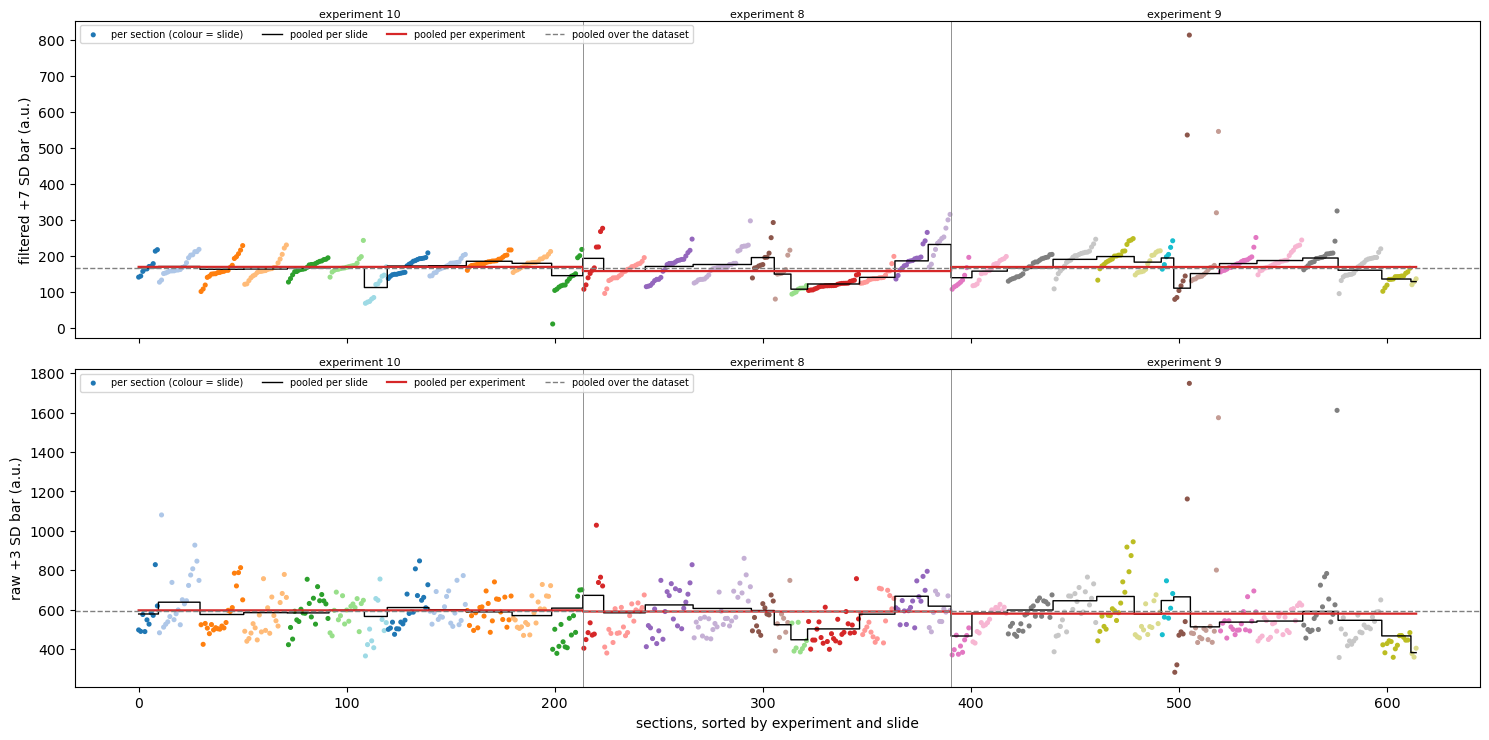

slides nested in experiments: True
share of the variance of the per-section values:
                         between experiments between slides, same experiment between sections, same slide
filtered +7 SD centre                    2 %                            20 %                         78 %
filtered +7 SD SD                        2 %                            23 %                         75 %
filtered +7 SD threshold                 2 %                            23 %                         75 %
raw +3 SD centre                         3 %                            19 %                         78 %
raw +3 SD SD                             1 %                            15 %                         85 %
raw +3 SD threshold                      1 %                            16 %                         83 %


In [4]:
order = THR.sort_values(["Experiment", "slide", "filtered section threshold"]).index
t = THR.loc[order]
x = np.arange(len(t))
fig, axes = plt.subplots(2, 1, figsize=(15, 7.5), sharex=True)
for ax, value in zip(axes, SD):
    codes = t["slide"].astype("category").cat.codes.to_numpy()
    ax.scatter(x, t[f"{value} section threshold"], s=7, c=plt.cm.tab20(codes % 20), label="per section (colour = slide)")
    ax.plot(x, t[f"{value} slide threshold"], drawstyle="steps-mid", color="black", lw=1, label="pooled per slide")
    ax.plot(x, t[f"{value} experiment threshold"], drawstyle="steps-mid", color="tab:red", lw=1.6, label="pooled per experiment")
    ax.axhline(t[f"{value} dataset threshold"].iloc[0], color="grey", ls="--", lw=1, label="pooled over the dataset")
    ex = t["Experiment"].to_numpy()
    for b in np.flatnonzero(ex[1:] != ex[:-1]):
        ax.axvline(b + 0.5, color="grey", lw=0.6)
    for e in pd.unique(ex):
        where = np.flatnonzero(ex == e)
        ax.text(where.mean(), 1.01, f"experiment {e}", transform=ax.get_xaxis_transform(), ha="center", fontsize=8)
    if (t[f"{value} section threshold"] > 0).all():
        ax.set_yscale("log")
    ax.set_ylabel(f"{SD_NAME[value]} bar (a.u.)")
    ax.legend(fontsize=7, loc="upper left", ncol=4)
axes[-1].set_xlabel("sections, sorted by experiment and slide")
fig.tight_layout()
plt.show()


def variance_shares(frame, column):
    y = frame[column].astype(float)
    y = np.log(y) if (y > 0).all() else y
    total = ((y - y.mean()) ** 2).mean()
    by_exp = y.groupby(frame["Experiment"]).transform("mean")
    by_slide = y.groupby(frame["slide"]).transform("mean")
    return {"between experiments": ((by_exp - y.mean()) ** 2).mean() / total,
            "between slides, same experiment": ((by_slide - by_exp) ** 2).mean() / total,
            "between sections, same slide": ((y - by_slide) ** 2).mean() / total}


nested = THR.groupby("slide")["Experiment"].nunique().max() == 1
print("slides nested in experiments:", nested)
shares = pd.DataFrame({f"{SD_NAME[v]} {part}": variance_shares(THR, f"{v} section {part}")
                       for v in SD for part in ("centre", "SD", "threshold")}).T
print("share of the variance of the per-section values:")
print((100 * shares).round(0).astype(int).astype(str).add(" %").to_string())

In [5]:
# Does the per-section bar itself differ by genotype? (slide means; Mann-Whitney)
rows = {}
for value in SD:
    for part in ("centre", "SD", "threshold"):
        col = f"{value} section {part}"
        slides = THR.groupby("slide").agg({col: "mean", "Genotype": "first"})
        a, b = (slides.loc[slides["Genotype"] == g, col] for g in GENOTYPES[:2])
        rows[f"{SD_NAME[value]} {part}"] = {f"{GENOTYPES[0]} median": a.median(), f"{GENOTYPES[1]} median": b.median(),
                                           f"{GENOTYPES[1]}/{GENOTYPES[0]}": b.median() / a.median() if a.median() else np.nan,
                                           "p (slides)": stats.mannwhitneyu(a, b).pvalue}
print("the per-section reference, by genotype (slide means):")
display(pd.DataFrame(rows).T.astype(float).round(4))

the per-section reference, by genotype (slide means):


,GD1 median,WT3 median,WT3/GD1,p (slides)
filtered +7 SD centre,3.0211,3.0833,1.0206,0.4478
filtered +7 SD SD,24.0586,24.2231,1.0068,0.9302
filtered +7 SD threshold,172.0308,172.6453,1.0036,0.9070
raw +3 SD centre,382.4595,381.9265,0.9986,0.4137
raw +3 SD SD,64.9155,61.8951,0.9535,0.5019
raw +3 SD threshold,577.8188,557.0414,0.9640,0.2933


## 3. How many cells each rule calls

Per section, the share of cells called positive in each region; the table gives the median over sections. **negative %** is a false-positive rate: cells deep in the organoid where AF488 is not at home should be negative (barring far migrants). For the two negative-control rules it is 1 % by construction. **home / negative** is the pooled positive rate at home over the pooled rate in the negative control — how far above the noise floor the labelled cells stand.

In [6]:
REGIONS = ("band", "home", "crossed", "neg")
records = []
names_rules = list(RULES)
together = np.zeros((len(RULES), len(RULES)), np.int64)        # cells near the line called by both rules
for _, row in counted.iterrows():
    n, d = row["name"], cells[row["name"]]
    calls = np.column_stack([positive(n, r) for r in names_rules])
    near = (d["band"] | d["home"] | d["crossed"])
    m = calls[near].astype(np.int64)
    together += m.T @ m
    length_mm = row[f"length {row['primary band']} (um)"] / 1000
    region_cells = {reg: int(d[reg].sum()) for reg in REGIONS}
    for j, rule in enumerate(names_rules):
        rec = {"name": n, "Genotype": row["Genotype"], "Experiment": row["Experiment"], "slide": row["slide"],
               "rule": rule, "length (mm)": length_mm if length_mm > 0 else np.nan}
        for reg in REGIONS:
            rec[f"{reg} cells"] = region_cells[reg]
            rec[f"{reg} +"] = int((calls[:, j] & d[reg]).sum())
        records.append(rec)
obs = pd.DataFrame(records)
obs["crossed per mm"] = obs["crossed +"] / obs["length (mm)"]
obs["home per mm"] = obs["home +"] / obs["length (mm)"]
near_pos = obs["crossed +"] + obs["home +"]
obs["share crossed"] = (obs["crossed +"] / near_pos.where(near_pos >= MIN_SHARE)).astype(float)
for reg in REGIONS:
    obs[f"{reg} %"] = 100 * obs[f"{reg} +"] / obs[f"{reg} cells"].where(obs[f"{reg} cells"] > 0)

pooled = obs.groupby("rule")[[f"{r} {s}" for r in REGIONS for s in ("+", "cells")]].sum()
calls_table = pd.DataFrame({
    "home %": obs.groupby("rule")["home %"].median(),
    "crossed %": obs.groupby("rule")["crossed %"].median(),
    "band %": obs.groupby("rule")["band %"].median(),
    "negative %": obs.groupby("rule")["neg %"].median(),
    "sections with negative > 1 %": obs.assign(x=obs["neg %"] > 1).groupby("rule")["x"].mean() * 100,
    "home / negative (pooled)": (pooled["home +"] / pooled["home cells"]) / (pooled["neg +"] / pooled["neg cells"]),
    "crossed per mm": obs.groupby("rule")["crossed per mm"].median(),
    "home per mm": obs.groupby("rule")["home per mm"].median(),
    "share crossed": obs.groupby("rule")["share crossed"].median(),
}).loc[names_rules]
print("median over sections (pooled where stated):")
display(calls_table.astype(float).round(3))

median over sections (pooled where stated):


,home %,crossed %,band %,negative %,sections with negative > 1 %,home / negative (pooled),crossed per mm,home per mm,share crossed
rule,,,,,,,,,
filtered +7 SD · section,1.206,0.212,0.228,0.038,4.715,12.546,11.657,61.971,0.167
filtered +7 SD · slide,1.125,0.204,0.223,0.042,5.041,11.618,11.163,57.681,0.173
filtered +7 SD · experiment,1.104,0.210,0.235,0.042,5.691,11.075,11.313,55.173,0.175
filtered +7 SD · dataset,1.065,0.211,0.233,0.043,5.691,11.151,11.303,54.662,0.173
raw +3 SD · section,4.725,1.968,2.170,0.588,40.650,4.308,106.002,244.687,0.294
raw +3 SD · slide,3.353,1.565,1.507,0.279,33.171,3.973,83.904,158.974,0.276
raw +3 SD · experiment,2.990,1.343,1.328,0.204,33.984,3.379,78.722,146.647,0.274
raw +3 SD · dataset,2.998,1.265,1.300,0.211,34.146,3.382,73.647,144.858,0.280
ring contrast ≥ 1.5,0.730,0.212,0.238,0.065,4.065,6.238,12.776,36.963,0.232


## 4. Do the rules agree?

Left: on cells near the line (band, home or crossed), the **Jaccard index** of two rules' positives — cells both call over cells either calls. Right: across sections, the **Spearman correlation** of crossed cells per mm. Two rules can call different cells and still rank the sections alike, which is what a genotype comparison needs.

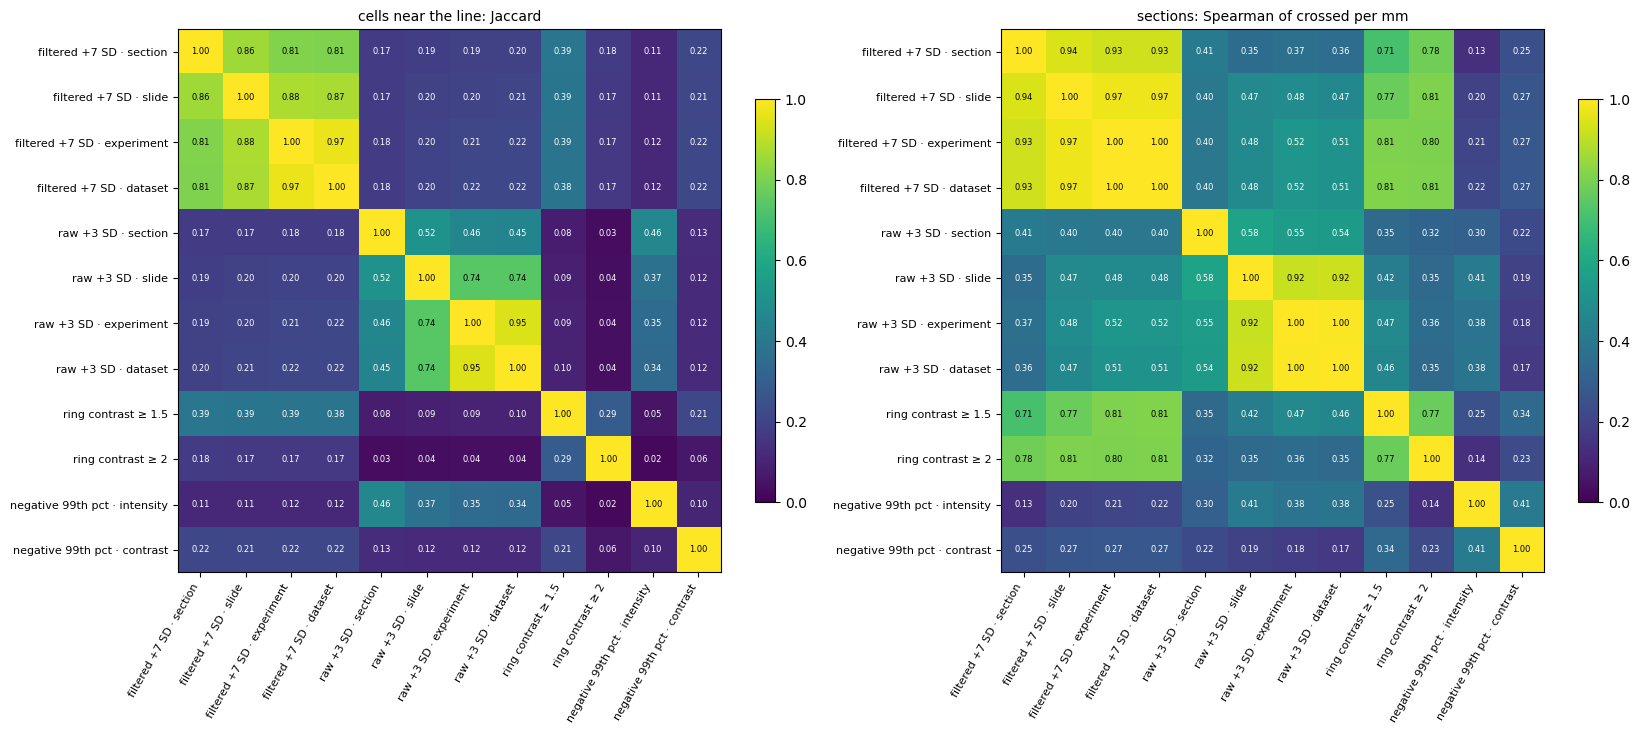

In [7]:
diag = np.diag(together).astype(float)
jaccard = together / (diag[:, None] + diag[None, :] - together)
wide = obs.pivot(index="name", columns="rule", values="crossed per mm")[names_rules]
spearman = wide.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(17, 7.2))
for ax, matrix, title in ((axes[0], jaccard, "cells near the line: Jaccard"),
                          (axes[1], spearman.to_numpy(), "sections: Spearman of crossed per mm")):
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(names_rules)), names_rules, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names_rules)), names_rules, fontsize=8)
    for i in range(len(names_rules)):
        for j in range(len(names_rules)):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if matrix[i, j] < 0.6 else "black")
    ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout()
plt.show()

**Pooling, section by section.** Crossed per mm under the filtered +7 SD rule, its bar set per section (x) against per slide and per experiment (y). Points off the diagonal are sections whose count depends on whose band set the bar.

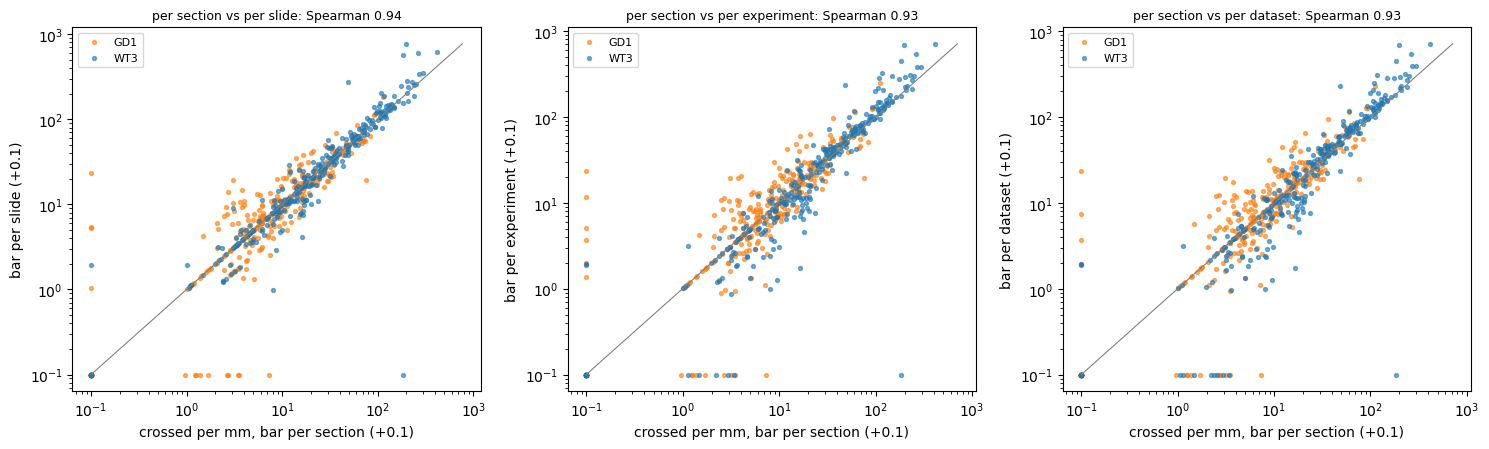

In [8]:
colours = dict(zip(GENOTYPES, ("tab:orange", "tab:blue", "tab:green")))
levels_vs = ["slide", "experiment", "dataset"]
fig, axes = plt.subplots(1, len(levels_vs), figsize=(5 * len(levels_vs), 4.6))
base = wide[MAIN]
for ax, level in zip(axes, levels_vs):
    other = wide[f"filtered +7 SD · {level}"]
    g = THR.loc[wide.index, "Genotype"]
    for genotype in GENOTYPES:
        ax.scatter(base[g == genotype] + 0.1, other[g == genotype] + 0.1, s=8, alpha=0.6, color=colours[genotype], label=genotype)
    top = max(base.max(), other.max()) + 1
    ax.plot([0.1, top], [0.1, top], color="grey", lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("crossed per mm, bar per section (+0.1)")
    ax.set_ylabel(f"bar per {level} (+0.1)")
    ax.set_title(f"per section vs per {level}: Spearman {stats.spearmanr(base, other, nan_policy='omit')[0]:.2f}", fontsize=9)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. The genotype result under each rule

For each rule: the mixed model (slide random, experiment fixed) on log(1 + crossed per mm), log(1 + home positives per mm), and logit share crossed — the fold change (odds ratio for the share) of the second genotype over the first, with its 95 % CI — and the slide-level Mann-Whitney test on slide means.

In [9]:
TERM = f"C(Genotype)[T.{GENOTYPES[1]}]"
OUTCOMES = {"crossed per mm": "log1p", "home per mm": "log1p", "share crossed": "logit"}


def mixed(frame, column, link):
    d = frame[["Genotype", "Experiment", "slide"]].copy()
    y = pd.to_numeric(frame[column], errors="coerce")
    d["y"] = np.log((y + 0.01) / (1 - y + 0.01)) if link == "logit" else np.log1p(y)
    d = d.dropna()
    fit = smf.mixedlm("y ~ C(Genotype) + C(Experiment)", d, groups=d["slide"]).fit(reml=True)
    lo, hi = fit.conf_int().loc[TERM]
    return {"fold": np.exp(fit.params[TERM]), "CI low": np.exp(lo), "CI high": np.exp(hi), "p": fit.pvalues[TERM],
            "sections": len(d), "converged": fit.converged}


def slide_test(frame, column):
    s = frame.groupby("slide").agg({column: "mean", "Genotype": "first"})
    a, b = (s.loc[s["Genotype"] == g, column].dropna() for g in GENOTYPES[:2])
    return {"slide ratio": b.median() / a.median() if a.median() else np.nan, "slide p": stats.mannwhitneyu(a, b).pvalue}


effects = []
for rule in names_rules:
    frame = obs[obs["rule"] == rule]
    for outcome, link in OUTCOMES.items():
        try:
            row = mixed(frame, outcome, link)
        except Exception as exc:
            row = {"fold": np.nan, "note": f"{type(exc).__name__}"}
        effects.append({"rule": rule, "outcome": outcome, **row, **slide_test(frame, outcome)})
effects = pd.DataFrame(effects)
for outcome in OUTCOMES:
    print(f"--- {outcome}: {GENOTYPES[1]} over {GENOTYPES[0]}" + (" (odds ratio)" if OUTCOMES[outcome] == "logit" else ""))
    display(effects[effects["outcome"] == outcome].drop(columns="outcome").set_index("rule").round(3))

--- crossed per mm: WT3 over GD1


,fold,CI low,CI high,p,sections,converged,slide ratio,slide p
rule,,,,,,,,
filtered +7 SD · section,1.910,1.193,3.059,0.007,615,True,1.863,0.023
filtered +7 SD · slide,1.863,1.166,2.976,0.009,615,True,1.755,0.033
filtered +7 SD · experiment,1.612,0.899,2.891,0.109,615,True,1.821,0.144
filtered +7 SD · dataset,1.603,0.889,2.887,0.116,615,True,2.052,0.161
raw +3 SD · section,1.313,0.871,1.980,0.194,615,True,1.383,0.029
raw +3 SD · slide,1.345,0.759,2.386,0.310,615,True,1.319,0.137
raw +3 SD · experiment,0.828,0.371,1.845,0.644,615,True,1.358,0.661
raw +3 SD · dataset,0.820,0.373,1.799,0.620,615,True,1.477,0.620
ring contrast ≥ 1.5,1.130,0.691,1.847,0.627,615,True,1.688,0.559


--- home per mm: WT3 over GD1


,fold,CI low,CI high,p,sections,converged,slide ratio,slide p
rule,,,,,,,,
filtered +7 SD · section,2.270,1.307,3.943,0.004,615,True,1.691,0.015
filtered +7 SD · slide,2.353,1.367,4.050,0.002,615,True,2.158,0.017
filtered +7 SD · experiment,1.988,1.046,3.776,0.036,615,True,1.586,0.044
filtered +7 SD · dataset,1.972,1.040,3.739,0.037,615,True,1.493,0.047
raw +3 SD · section,4.189,2.685,6.536,0.000,615,True,3.036,0.000
raw +3 SD · slide,3.772,2.082,6.833,0.000,615,True,2.772,0.000
raw +3 SD · experiment,2.156,0.991,4.689,0.053,615,True,1.711,0.017
raw +3 SD · dataset,2.157,0.986,4.719,0.054,615,True,1.664,0.012
ring contrast ≥ 1.5,1.554,0.939,2.571,0.086,615,True,1.347,0.102


--- share crossed: WT3 over GD1 (odds ratio)


,fold,CI low,CI high,p,sections,converged,slide ratio,slide p
rule,,,,,,,,
filtered +7 SD · section,0.931,0.739,1.173,0.546,583,True,0.951,1.000
filtered +7 SD · slide,0.865,0.681,1.098,0.233,580,True,0.888,0.502
filtered +7 SD · experiment,0.887,0.699,1.125,0.323,572,True,1.019,0.748
filtered +7 SD · dataset,0.864,0.667,1.119,0.267,572,True,0.995,0.599
raw +3 SD · section,0.330,0.223,0.488,0.000,609,True,0.536,0.000
raw +3 SD · slide,0.367,0.238,0.564,0.000,599,True,0.517,0.000
raw +3 SD · experiment,0.327,0.201,0.530,0.000,587,True,0.534,0.000
raw +3 SD · dataset,0.327,0.202,0.529,0.000,587,True,0.522,0.000
ring contrast ≥ 1.5,0.704,0.550,0.901,0.005,582,True,0.841,0.007


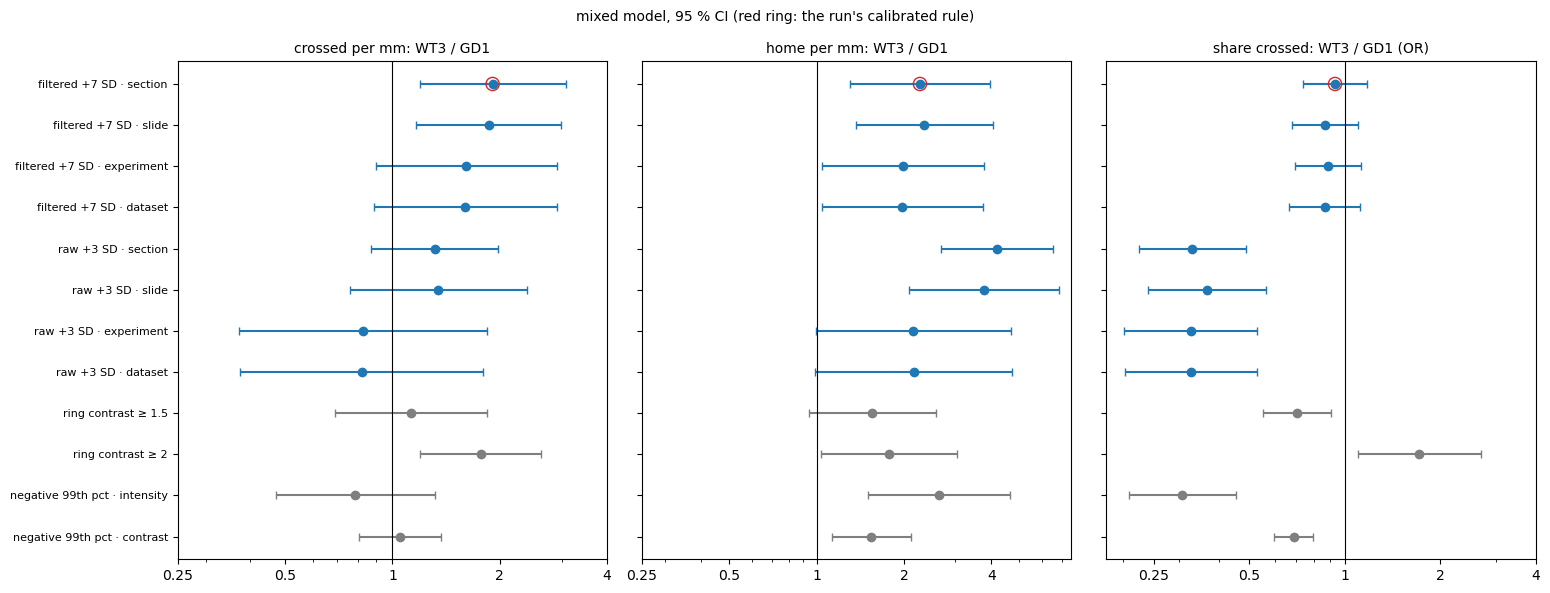

In [10]:
fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(5.2 * len(OUTCOMES), 6), sharey=True)
y = np.arange(len(names_rules))[::-1]
for ax, outcome in zip(axes, OUTCOMES):
    e = effects[effects["outcome"] == outcome].set_index("rule").loc[names_rules]
    sd_rule = np.array([RULES[r][0] == "sd" for r in names_rules])
    for mask, colour in ((sd_rule, "tab:blue"), (~sd_rule, "tab:grey")):
        ax.errorbar(e["fold"][mask], y[mask], xerr=[(e["fold"] - e["CI low"])[mask], (e["CI high"] - e["fold"])[mask]],
                    fmt="o", color=colour, capsize=3)
    main = names_rules.index(MAIN)
    ax.scatter(e["fold"].iloc[main], y[main], s=90, facecolors="none", edgecolors="tab:red", zorder=3)
    ax.axvline(1, color="black", lw=0.8)
    ax.set_xscale("log")
    ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(f"{outcome}: {GENOTYPES[1]} / {GENOTYPES[0]}" + (" (OR)" if OUTCOMES[outcome] == "logit" else ""), fontsize=10)
axes[0].set_yticks(y, names_rules, fontsize=8)
fig.suptitle("mixed model, 95 % CI (red ring: the run's calibrated rule)", fontsize=10)
fig.tight_layout()
plt.show()

**Per experiment.** The same comparison inside each experiment (section medians, Mann-Whitney): whether a rule changes which batches show the difference.

In [11]:
per_exp = {}
for rule in names_rules:
    frame = obs[obs["rule"] == rule]
    for e, part in frame.groupby("Experiment"):
        for outcome in ("crossed per mm", "share crossed"):
            a, b = (part.loc[part["Genotype"] == g, outcome].dropna() for g in GENOTYPES[:2])
            if len(a) >= 3 and len(b) >= 3:
                per_exp[(rule, f"exp {e} {outcome}")] = f"{b.median() / a.median() if a.median() else np.nan:.2f} (p {stats.mannwhitneyu(a, b).pvalue:.2g})"
table = pd.Series(per_exp).unstack()
print(f"{GENOTYPES[1]}/{GENOTYPES[0]} ratio of section medians (Mann-Whitney p), per experiment:")
display(table.loc[[r for r in names_rules if r in table.index]])

WT3/GD1 ratio of section medians (Mann-Whitney p), per experiment:


,exp 10 crossed per mm,exp 10 share crossed,exp 8 crossed per mm,exp 8 share crossed,exp 9 crossed per mm,exp 9 share crossed
filtered +7 SD · section,3.38 (p 6.1e-11),0.99 (p 0.89),1.21 (p 0.25),0.78 (p 0.26),4.66 (p 1.1e-10),0.89 (p 0.18)
filtered +7 SD · slide,2.65 (p 4.9e-08),0.96 (p 0.57),1.14 (p 0.44),0.67 (p 0.2),4.50 (p 5.6e-10),0.86 (p 0.097)
filtered +7 SD · experiment,2.83 (p 1.8e-08),1.01 (p 0.98),1.01 (p 0.79),0.74 (p 0.45),4.80 (p 1.5e-07),0.80 (p 0.029)
filtered +7 SD · dataset,2.67 (p 3.1e-08),0.98 (p 0.84),1.06 (p 0.87),0.70 (p 0.37),4.68 (p 1.8e-07),0.79 (p 0.02)
raw +3 SD · section,0.80 (p 0.93),0.58 (p 5e-05),1.50 (p 0.21),0.44 (p 0.0018),2.14 (p 6.3e-07),0.24 (p 2.3e-12)
raw +3 SD · slide,0.78 (p 0.8),0.58 (p 0.0029),1.28 (p 0.34),0.51 (p 0.026),2.83 (p 0.00033),0.25 (p 1.8e-08)
raw +3 SD · experiment,0.78 (p 0.89),0.59 (p 0.0052),0.68 (p 0.62),0.57 (p 0.0087),0.98 (p 0.94),0.23 (p 1.7e-10)
raw +3 SD · dataset,0.75 (p 0.75),0.64 (p 0.0047),0.70 (p 0.62),0.57 (p 0.0092),1.08 (p 0.85),0.23 (p 1.8e-10)
ring contrast ≥ 1.5,1.53 (p 0.0015),0.85 (p 0.085),0.67 (p 0.098),0.68 (p 0.029),2.53 (p 4.3e-05),0.80 (p 0.014)
ring contrast ≥ 2,nan (p 1.7e-08),2.94 (p 0.025),nan (p 0.26),1.78 (p 0.2),8.61 (p 1.1e-08),1.44 (p 0.02)


### What it showed (22 October 2026: 615 counted sections, 38 slides, 10.5 million cells near the lines)

**The recomputation is exact.** At section level the filtered +7 SD, raw +3 SD and ring-contrast ≥ 1.5 rules call exactly the cells the run called (0 differences), so everything here is comparable with `whole_dataset.ipynb`.

**There is no batch to correct.** 75–85 % of the variance of the per-section bar is between sections on the same slide; only 1–3 % is between experiments and 15–23 % between slides. The bar does not differ by genotype (filtered +7 SD: 172 vs 173, p 0.91 on slide means). So pooling the reference per slide or experiment mostly removes section-to-section variation, not a staining or imaging batch, and the per-section bar is not biased by genotype.

**The calibrated rule hardly depends on the level.** Filtered +7 SD per section, slide, experiment or dataset calls largely the same cells (Jaccard 0.81–0.97) and ranks the sections the same way (Spearman 0.93–1.00). It keeps a negative-control rate of about 0.04 % and puts labelled cells 11–12× above that floor. Under all four levels:
- **home positives per mm**: WT3 2.0–2.4× GD1 (mixed model p ≤ 0.04);
- **share crossed**: equal (OR 0.86–0.93, all p > 0.2);
- **crossed per mm**: 1.9× with the bar per section or slide (p 0.007, 0.009), but 1.6× and not significant with the bar pooled per experiment or dataset (CI 0.9–2.9, p 0.11). Within experiments 9 and 10 the difference is 2.7–4.8× at every level (p < 1e-7); in experiment 8 it is absent at every level. The mixed model's p for crossed per mm therefore depends on how the bar is set; the per-experiment pattern does not.

**The noisy rules give a different and misleading answer.** Raw +3 SD (any level) and the negative-control 99th percentile on intensity call 0.2–1 % of negative-control cells positive, 5–27× more than the calibrated rule. Under raw +3 SD, labelled cells stand only 3–4× above that floor (12× for the calibrated rule). Both rules call 6–13× more cells crossed per mm. Under these rules:
- the crossed-per-mm difference disappears;
- WT3's share crossed drops (OR 0.31–0.37).

That is what noise does: it adds a similar number of false positives on both sides of the line, which dilutes the share most where there are more true labelled cells at home (WT3). It is not evidence of less migration. Ring contrast ≥ 1.5 sits in between (negative 0.065 %, share OR 0.70). Contrast ≥ 2 calls almost nothing (median 1 crossed cell per mm), and its share model did not converge.

**What holds whatever the rule.** WT3 has more AF488-positive cells on its own side of the junction: 1.5–4.2× under all 12 rules, p < 0.05 in 9 of them. No rule with an acceptable false-positive rate makes a labelled WT3 cell more likely to have crossed.

**Decision.**
- Keep the calibrated rule with its bar set per section: pooling corrects no batch and only weakens the crossed-per-mm test.
- Report home positives and the share crossed as the robust results.
- Report crossed per mm with the caveat that its overall significance depends on the bar, while the per-experiment pattern (9 and 10 yes, 8 no) does not.

**Caveats.**
- Two sections have almost no band: 045-044_s17 has 0 band cells, so no per-section bar and nothing called; 037-036_s21 has 1 band cell, so its per-section bar is that one cell. Both are automatic bands.
- The automatic bands are not reviewed.
- The rule was validated against one person's clicks on 30 sections (`positivity_metrics.ipynb`).